# 07 · Le réseau de similarité des Pokémon

L'idée : on décrit chaque Pokémon par un **vecteur** (ses types, ses stats, son gabarit, sa forme, ses couleurs), on relie chaque Pokémon à ceux qui lui ressemblent le plus (**graphe des k plus proches voisins**, comme au TP4), puis on analyse ce graphe avec les outils du TP3 : communautés (Louvain), centralités, comparaison avec un graphe aléatoire.

La question derrière : **est-ce que la place d'un Pokémon dans ce réseau dit quelque chose de sa popularité ?** Par exemple, un Pokémon « unique » (peu de voisins proches) est-il plus aimé qu'un Pokémon qui ressemble à plein d'autres ? Les Pokémon populaires se ressemblent-ils entre eux ?

Enfin on fait un **node2vec** (marches aléatoires + Word2Vec, comme au TP4) et un **t-SNE** pour avoir une carte 2D du réseau.

Pour la popularité, on reste sur ce qu'on a fait dans les notebooks 01 et 02 : pas de score combiné, chaque source est regardée à part, en **percentile dans la génération** (comme dans les notebooks 04 et 06). Pokémon of the Year 2020 vient en quatrième source, à part, parce qu'on n'en connaît que le top 30 de chaque génération (section 6).

À la fin, on refait les tests **sans la couleur officielle** (section 7), pour savoir à quel point nos conclusions dépendent de ce choix.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from networkx.algorithms.community import louvain_communities, modularity
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE, trustworthiness

pd.set_option("display.max_columns", 50)
SEED = 0   # graine fixe pour que les résultats soient reproductibles
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
couleurs = pd.read_csv(OUT / "couleurs_sprites.csv", index_col="dex")
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
sur = pd.read_csv(OUT / "sur_sous_cotes.csv", index_col="dex")
print(table.shape, couleurs.shape, pop.shape, sur.shape)

(1025, 35) (1025, 15) (1025, 19) (1025, 13)


## 1. Le vecteur de chaque Pokémon

On décrit chaque Pokémon par **6 blocs** de variables, qui parlent uniquement de son apparence et de son rôle en jeu :
- **types** : une colonne par type (18), qui vaut 1 si le Pokémon a ce type, en premier ou en second ;
- **stats** : les 6 statistiques de combat ;
- **gabarit** : taille et poids, en log (le poids va de 0,1 kg à 999,9 kg, sans le log quelques géants écraseraient tout) ;
- **couleur officielle** (PokéAPI) en indicatrices ;
- **forme du corps** (PokéAPI) en indicatrices ;
- **couleurs de l'image** (notebook 03, sans le contour noir) : nombre de couleurs, saturation et luminosité, teinte dominante.

On a hésité pour la couleur officielle et la forme du corps, parce que ce sont des étiquettes un peu grossières. On décide quand même de **les garder** : ce sont des attributs de design, exactement ce qu'on veut comparer, et la forme du corps est la seule info qu'on a sur la silhouette du Pokémon. On verra plus bas qu'elles pèsent beaucoup dans les communautés.

On ne met **pas** la génération, le stade, starter ou légendaire, ni la popularité : on veut un réseau de ressemblance « physique », pour ensuite regarder comment la popularité s'y répartit. Si on mettait la popularité dedans, on retrouverait forcément des voisins populaires, et ça ne voudrait rien dire.

In [2]:
# types : un Pokémon peut en avoir deux
types = pd.get_dummies(table["type1"]).astype(int).add(pd.get_dummies(table["type2"]).astype(int).reindex(columns=pd.get_dummies(table["type1"]).columns, fill_value=0), fill_value=0)
print("types :", types.shape, "| valeurs :", np.unique(types.values))
stats = table[["pv", "attaque", "defense", "attaque_spe", "defense_spe", "vitesse"]]
gabarit = np.log(table[["taille_m", "poids_kg"]]).add_prefix("log_")
couleur_off = pd.get_dummies(table["couleur"], prefix="coul").astype(int)
forme = pd.get_dummies(table["forme_corps"], prefix="forme").astype(int)
# la teinte est un angle (0° = 360° = rouge) : on la passe en cosinus et sinus pour que 359° soit proche de 1°
t = np.deg2rad(couleurs["dom_teinte"])
sprite = pd.DataFrame({"nb_couleurs": couleurs["nb_couleurs"], "sat_moy": couleurs["saturation_moyenne"],
                       "lum_moy": couleurs["luminosite_moyenne"], "dom_sat": couleurs["dom_saturation"],
                       "teinte_cos": np.cos(t), "teinte_sin": np.sin(t)})
blocs = {"types": types, "stats": stats, "gabarit": gabarit, "couleur_off": couleur_off, "forme": forme, "sprite": sprite}
for nom, b in blocs.items():
    print(f"{nom:12s} {b.shape[1]:3d} colonnes | manquants : {b.isna().sum().sum()}")

types : (1025, 18) | valeurs : [0 1]
types         18 colonnes | manquants : 0
stats          6 colonnes | manquants : 0
gabarit        2 colonnes | manquants : 0
couleur_off   10 colonnes | manquants : 0
forme         14 colonnes | manquants : 0
sprite         6 colonnes | manquants : 0


On a 56 colonnes en tout, réparties en 6 blocs, et aucun manquant. Les types valent bien 0 ou 1 (un Pokémon n'a jamais deux fois le même type).

**Pondération.** Si on colle les blocs tels quels, le bloc qui a le plus de colonnes (les 18 types) pèse beaucoup plus que le gabarit (2 colonnes). On n'a pas de raison de dire que le type compte plus que la taille pour juger si deux Pokémon se ressemblent, donc on décide de donner **le même poids à chaque bloc** :
1. on **standardise** chaque colonne (moyenne 0, écart-type 1), comme au TP2 ;
2. on divise chaque bloc par la racine de son nombre de colonnes, pour que chaque bloc ait le même poids total dans la distance.

In [3]:
parties = []
for nom, b in blocs.items():
    z = StandardScaler().fit_transform(b.astype(float))
    parties.append(pd.DataFrame(z / np.sqrt(b.shape[1]), index=b.index, columns=[f"{nom}:{c}" for c in b.columns]))
X = pd.concat(parties, axis=1).loc[table.index]
print(X.shape)
# vérification : la variance totale de chaque bloc
X.var(ddof=0).groupby(X.columns.str.split(":").str[0]).sum().round(2)

(1025, 56)


couleur_off    1.0
forme          1.0
gabarit        1.0
sprite         1.0
stats          1.0
types          1.0
dtype: float64

Après la pondération, chaque bloc a bien une variance totale de 1 : aucun bloc ne domine juste parce qu'il a plus de colonnes.

### Ce qu'on a fait et pourquoi

**1. Décrire chaque Pokémon par un vecteur.** Pour construire un réseau de ressemblance, il faut d'abord pouvoir dire « à quel point deux Pokémon se ressemblent ». On a donc mis chaque Pokémon sous forme d'un vecteur de 56 nombres qui décrivent son apparence et son rôle en jeu (types, stats, gabarit, couleur, forme, couleurs de l'image).

**2. Ne pas mettre la popularité (ni la génération) dedans.** Le but, c'est de regarder ensuite comment la popularité se répartit dans le réseau. Si la popularité était dans le vecteur, les Pokémon populaires seraient forcément voisins entre eux, et le résultat serait truqué d'avance.

**3. Les indicatrices et la teinte en cosinus/sinus.** Les variables qualitatives (types, couleur officielle, forme) sont passées en colonnes 0/1, parce qu'un calcul de distance ne sait pas comparer du texte. Pour la teinte, on a utilisé le cosinus et le sinus de l'angle : sinon 359° et 1° (deux rouges) seraient vus comme les plus éloignés possibles.

**4. Le log pour le gabarit.** Comme dans le notebook 06, la taille et le poids vont de minuscules à gigantesques, donc on passe en log pour que quelques géants ne dominent pas la distance.

**5. Standardiser, puis donner le même poids à chaque bloc.** On standardise chaque colonne (comme au TP2) pour qu'aucune unité ne domine. Mais ça ne suffit pas : le bloc des types a 18 colonnes et le gabarit 2, donc les types pèseraient 9 fois plus dans la distance. On divise chaque bloc par la racine de son nombre de colonnes pour que chaque bloc ait la même variance totale. On l'a vérifié dans la cellule juste au-dessus. On n'avait aucune raison de dire qu'un bloc compte plus qu'un autre, donc on les a mis à égalité.

## 2. Le graphe des k plus proches voisins

On mesure la ressemblance avec la **similarité cosinus** (comme au TP4). Chaque Pokémon est relié à ses k plus proches voisins ; si A est dans les voisins de B ou B dans ceux de A, on met une arête (le graphe est non orienté), avec un poids égal à la similarité.

D'abord, l'effet de k sur le graphe :

In [4]:
nn = NearestNeighbors(metric="cosine").fit(X.values)
dist, idx = nn.kneighbors(X.values, n_neighbors=31)
noeuds = X.index.to_numpy()

def graphe_knn(k):
    G = nx.Graph()
    G.add_nodes_from(noeuds)
    for i in range(len(noeuds)):
        for j, d in zip(idx[i, 1:k + 1], dist[i, 1:k + 1]):
            G.add_edge(noeuds[i], noeuds[j], weight=1 - d)
    return G

lignes = []
for k in [2, 3, 5, 8, 10, 15, 20, 30]:
    g = graphe_knn(k)
    cc = list(nx.connected_components(g))
    lignes.append({"k": k, "aretes": g.number_of_edges(), "composantes": len(cc),
                   "taille plus grande": max(map(len, cc)), "degre moyen": 2 * g.number_of_edges() / g.number_of_nodes()})
effet_k = pd.DataFrame(lignes)
effet_k.set_index("k").round(1)

,aretes,composantes,taille plus grande,degre moyen
k,,,,
2,1509,3,1010,2.9
3,2228,1,1025,4.3
5,3601,1,1025,7.0
8,5673,1,1025,11.1
10,7017,1,1025,13.7
15,10332,1,1025,20.2
20,13546,1,1025,26.4
30,20008,1,1025,39.0


Avec k = 2, le graphe est coupé en 3 morceaux. Dès k = 3, tous les Pokémon sont dans une seule composante. Plus k augmente, plus il y a d'arêtes.

On choisit **k = 10**. Avec moins (3 à 5), le graphe est connexe mais très « maigre » : un Pokémon n'a que quelques voisins, et une seule ressemblance un peu bizarre change beaucoup sa place. Avec beaucoup plus (20, 30), on relie des Pokémon qui ne se ressemblent plus vraiment et les groupes se mélangent. 10, c'est le même ordre de grandeur que ce qu'on a utilisé au TP4. Avec k = 10, chaque Pokémon a en moyenne 13,7 voisins (plus que 10, parce qu'on garde aussi l'arête quand A a choisi B mais pas l'inverse).

In [5]:
K = 10
G = graphe_knn(K)
for n in G:
    G.nodes[n]["nom"] = table.loc[n, "nom_fr"]
print(G)
degres = pd.Series(dict(G.degree()))
degres.describe()

Graph with 1025 nodes and 7017 edges


count    1025.000000
mean       13.691707
std         3.949953
min        10.000000
25%        11.000000
50%        12.000000
75%        15.000000
max        31.000000
dtype: float64

Le graphe final a 1 025 nœuds et 7 017 arêtes. Le degré va de 10 (le minimum, ses 10 propres voisins) à 31.

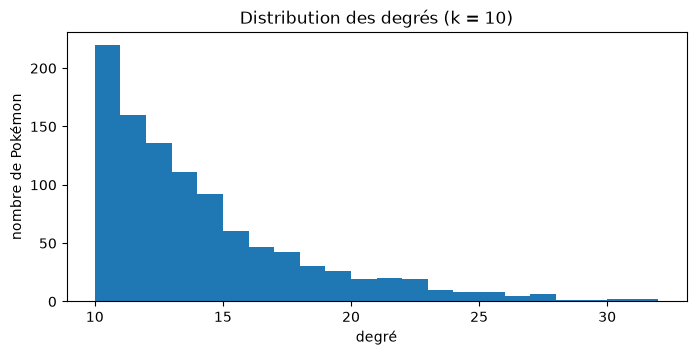

Pokémon les plus « connectés » :


Carapuce      31
Galeking      31
Aligatueur    30
Ama-Ama       30
Melmetal      29
Palkia        28
Maganon       27
Ponchiot      27
Korillon      27
Groudon       27
dtype: int64

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(degres, bins=range(degres.min(), degres.max() + 2))
ax.set_xlabel("degré"); ax.set_ylabel("nombre de Pokémon")
ax.set_title(f"Distribution des degrés (k = {K})")
plt.show()
print("Pokémon les plus « connectés » :")
degres.sort_values(ascending=False).head(10).rename(table["nom_fr"])

Les Pokémon avec le plus de voisins (Carapuce, Miraidon, Ama-Ama, Melmetal…) ressemblent à beaucoup d'autres : ils sont choisis comme voisins par plein de Pokémon.

In [7]:
# les voisins de quelques Pokémon connus : est-ce que le graphe a du sens ?
for d in [6, 25, 94, 133, 448]:
    v = sorted(G[d], key=lambda n: -G[d][n]["weight"])[:6]
    print(f"{table.loc[d, 'nom_fr']:12s} →", ", ".join(table.loc[v, "nom_fr"]))

Dracaufeu    → Magmar, Goupelin, Aflamanoir, Maganon, Braségali, Ho-Oh
Pikachu      → Pohm, Pichu, Posipi, Voltoutou, Négapi, Élekid
Ectoplasma   → Nidoking, Salarsen, Mewtwo, Wimessir, Magirêve, Mandrillon
Évoli        → Ponchiot, Manglouton, Keunotor, Ratentif, Laporeille, Rattatac
Lucario      → Pingoléon, Cobaltium, Lézargus, Charkos, Karaclée, Riolu


Les voisins ont du sens : Dracaufeu est entouré de Pokémon Feu rouges et dressés (Maganon, Magmar, Goupelin, Braségali), Pikachu de petits Pokémon Électrik jaunes (Pohm, Pichu, Posipi, Voltoutou, Négapi), Lucario de Pokémon Combat/Acier dressés (Pingoléon, Cobaltium, Riolu). Évoli, lui, est mis avec des petits mammifères marron (Ponchiot, Keunotor, Ratentif…) : le réseau ne voit que l'apparence, pas la popularité.

### Comparaison avec un graphe aléatoire de même taille (comme au TP3)

In [8]:
n, m = G.number_of_nodes(), G.number_of_edges()
rand = nx.gnm_random_graph(n, m, seed=SEED)
def resume(g):
    cc = g.subgraph(max(nx.connected_components(g), key=len))
    return [g.number_of_nodes(), g.number_of_edges(), nx.density(g), nx.transitivity(g), nx.average_clustering(g),
            cc.number_of_nodes(), nx.average_shortest_path_length(cc), nx.diameter(cc)]
comparaison = pd.DataFrame({"Pokémon (kNN)": resume(G), "Aléatoire G(n,m)": resume(rand)},
    index=["nœuds", "arêtes", "densité", "transitivité", "clustering moyen", "taille LCC", "plus court chemin moyen (LCC)", "diamètre (LCC)"])
comparaison.round(3)

,Pokémon (kNN),"Aléatoire G(n,m)"
nœuds,1025.000,1025.000
arêtes,7017.000,7017.000
densité,0.013,0.013
transitivité,0.316,0.014
clustering moyen,0.326,0.014
taille LCC,1025.000,1025.000
plus court chemin moyen (LCC),3.705,2.910
diamètre (LCC),6.000,5.000


Comparé à un graphe aléatoire de même taille, notre graphe a un **clustering bien plus fort** (0,33 contre 0,01) : les voisins d'un Pokémon se ressemblent aussi entre eux, il y a des « familles ». Les chemins sont un peu plus longs (3,7 contre 2,9, diamètre 6 contre 5), ce qui est normal pour un graphe de similarité, mais ça reste court : on va de n'importe quel Pokémon à n'importe quel autre en moins de 4 étapes en moyenne.

### Ce qu'on a fait et pourquoi

**1. La similarité cosinus.** On compare la **direction** des vecteurs plutôt que leur longueur, comme au TP4. Deux Pokémon qui ont le même « profil » (mêmes blocs au-dessus ou en dessous de la moyenne) sont proches, même si l'un est un peu plus extrême que l'autre.

**2. Un graphe des k plus proches voisins plutôt qu'un seuil.** On aurait pu relier tous les couples au-dessus d'une similarité fixe, mais alors certains Pokémon très « à part » n'auraient aucun voisin, et les zones denses auraient des centaines d'arêtes. Avec les k plus proches voisins, chaque Pokémon a au moins k voisins. On a symétrisé (une arête si A choisit B **ou** B choisit A) pour avoir un graphe non orienté, ce que demandent Louvain et la plupart des centralités.

**3. Le choix de k.** On a fait un tableau de l'effet de k (nombre de morceaux, d'arêtes, degré moyen) avant de choisir. Trop petit, le graphe est coupé ou fragile (une seule ressemblance bizarre change tout) ; trop grand, on relie des Pokémon qui ne se ressemblent plus. On a pris k = 10, assez pour que le graphe soit d'un seul morceau et stable, et du même ordre qu'au TP4.

**4. L'histogramme des degrés et les voisins de Pokémon connus.** L'histogramme montre comment les arêtes sont réparties (est-ce que quelques Pokémon sont des « hubs » ?). Regarder les voisins de Dracaufeu, Pikachu, Évoli… c'est notre test de bon sens : si les voisins n'avaient aucun sens, tout le reste de l'analyse ne vaudrait rien.

**5. La comparaison avec un graphe aléatoire de même taille (TP3).** Un chiffre comme « clustering = 0,3 » ne veut rien dire tout seul. On le compare à un graphe aléatoire G(n, m) avec autant de nœuds et d'arêtes : si notre graphe a beaucoup plus de clustering, c'est qu'il y a de vraies « familles » de Pokémon, et pas juste l'effet du nombre d'arêtes.

## 3. Les communautés (Louvain)

Comme au TP3/TP4, on cherche des groupes de Pokémon très reliés entre eux et peu reliés au reste, avec l'algorithme de **Louvain** (pondéré par la similarité). La **modularité** dit si le découpage est meilleur qu'un découpage au hasard (0 = pas mieux, plus c'est proche de 1 plus les groupes sont nets).

Louvain a une part de hasard : on le relance avec plusieurs graines pour voir si le résultat est stable.

In [9]:
from sklearn.metrics import adjusted_rand_score
essais = {s: louvain_communities(G, weight="weight", seed=s) for s in range(10)}
def etiquettes(comms):
    lab = {}
    for i, c in enumerate(sorted(comms, key=len, reverse=True)):
        for n in c:
            lab[n] = i
    return pd.Series(lab).sort_index()
labs = {s: etiquettes(c) for s, c in essais.items()}
print("nombre de communautés :", [len(c) for c in essais.values()])
print("modularité :", [round(modularity(G, c, weight="weight"), 3) for c in essais.values()])
ari = [adjusted_rand_score(labs[0], labs[s]) for s in range(1, 10)]
print("accord avec la graine 0 (ARI) : min", round(min(ari), 2), "| moyenne", round(np.mean(ari), 2))

nombre de communautés : [15, 15, 14, 15, 15, 14, 14, 17, 14, 14]
modularité : [np.float64(0.714), np.float64(0.711), np.float64(0.712), np.float64(0.717), np.float64(0.717), np.float64(0.715), np.float64(0.713), np.float64(0.715), np.float64(0.715), np.float64(0.715)]
accord avec la graine 0 (ARI) : min 0.81 | moyenne 0.85


Louvain trouve entre 14 et 17 communautés selon la graine, avec une modularité toujours autour de **0,71-0,72**. Les découpages se ressemblent bien d'une graine à l'autre (ARI moyen 0,85, au pire 0,81), donc le résultat est assez stable : ce sont surtout quelques petits groupes qui sont coupés ou fusionnés différemment.

Comme les graines donnent à peu près le même résultat, on décide simplement de **garder la graine 0** pour la suite, pour que tout soit reproductible.

In [10]:
communautes = essais[SEED]
comm = labs[SEED].rename("communaute")
print(f"{len(communautes)} communautés, modularité = {modularity(G, communautes, weight='weight'):.3f}")
comm.value_counts().sort_index()

15 communautés, modularité = 0.714


communaute
0     115
1     106
2     101
3      96
4      91
5      91
6      89
7      72
8      56
9      47
10     44
11     39
12     36
13     22
14     20
Name: count, dtype: int64

Avec la graine 0 : 15 communautés, de 20 à 115 Pokémon.

In [11]:
# modularité d'un graphe aléatoire de même taille, pour comparer
mod_rand = modularity(rand, louvain_communities(rand, seed=SEED))
print("modularité Louvain sur le graphe aléatoire :", round(mod_rand, 3))

modularité Louvain sur le graphe aléatoire : 0.226


Sur un graphe aléatoire, Louvain n'arrive qu'à 0,23 de modularité. Les communautés de notre graphe sont donc bien réelles.

### Qui est dans chaque communauté ?

In [12]:
d = table.join(comm)
def top(s, n=3):
    v = s.value_counts(normalize=True).head(n)
    return ", ".join(f"{k} {p:.0%}" for k, p in v.items())
desc = d.groupby("communaute").agg(
    n=("nom_fr", "size"),
    types=("type1", lambda s: top(pd.concat([s, d.loc[s.index, "type2"].dropna()]))),
    couleur=("couleur", top),
    forme=("forme_corps", lambda s: top(s, 2)),
    poids_median=("poids_kg", "median"),
    total_stats_moyen=("total_stats", "mean"),
    exemples=("nom_fr", lambda s: ", ".join(s.loc[d.loc[s.index, "total_stats"].sort_values(ascending=False).index[:4]])),
)
desc.round(1)

,n,types,couleur,forme,poids_median,total_stats_moyen,exemples
communaute,,,,,,,
0,115,"grass 41%, dragon 11%, poison 7%","green 90%, blue 3%, purple 3%","humanoid 24%, upright 24%",22.0,439.4,"Rayquaza, Celebi, Tyranocif, Shaymin"
1,106,"water 33%, dragon 9%, psychic 8%","blue 93%, white 3%, purple 3%","upright 41%, quadruped 19%",41.3,462.1,"Éthernatos, Dialga, Lunala, Xerneas"
2,101,"poison 15%, ghost 14%, psychic 12%","purple 67%, green 8%, gray 6%","ball 38%, upright 14%",11.5,407.2,"Mewtwo, Palkia, Muplodocus, Genesect"
3,96,"ice 15%, fairy 11%, normal 9%","white 77%, blue 8%, gray 5%","quadruped 22%, heads 17%",32.8,436.3,"Arceus, Lugia, Solgaleo, Reshiram"
4,91,"steel 16%, rock 11%, normal 11%","gray 92%, purple 3%, blue 2%","quadruped 34%, upright 23%",60.0,454.2,"Kyurem, Melmetal, Ékaïser, Glaivodo"
5,91,"normal 27%, ground 18%, fire 9%","brown 99%, red 1%","quadruped 54%, upright 25%",34.5,416.9,"Monaflèmit, Heatran, Volcanion, Démétéros"
6,89,"fire 28%, fighting 10%, flying 8%","red 75%, blue 10%, brown 7%","upright 33%, tentacles 25%",39.0,461.9,"Ho-Oh, Yveltal, Groudon, Koraidon"
7,72,"electric 28%, psychic 11%, fire 9%",yellow 100%,"quadruped 29%, upright 26%",23.8,436.8,"Victini, Zeraora, Jirachi, Ire-Foudre"
8,56,"fairy 26%, psychic 19%, normal 18%",pink 100%,"humanoid 34%, upright 30%",14.4,405.8,"Mew, Diancie, Créfollet, Amovénus"


Les communautés se lisent assez facilement, et elles suivent surtout **la couleur officielle et la forme du corps** :
- la plupart sont presque d'une seule couleur : jaune à 100 % (7, avec beaucoup d'Électrik), rose à 100 % (8, Fée/Psy), marron à 99 % (5), bleue à 93 % (1, Eau), grise à 92 % (4, Acier/Roche), verte à 90 % (0, Plante), noire à 89 % (9 : Giratina, Zekrom, Darkrai, Necrozma…), blanche à 77 % (3), rouge à 75 % (6, Feu), violette à 67 % (2, Poison/Spectre) ;
- d'autres sont définies par une forme : 95 % « armure » (11, Insectes et crustacés à carapace), 100 % « poisson » (12, Lokhlass, Oratoria…), 100 % « ailes d'insecte » (13), 100 % « pattes » (14) et 77 % « ailes » (10, les oiseaux).

C'est ce qu'on avait prévu en gardant ces deux variables : comme un Pokémon n'a qu'une couleur officielle et qu'une forme, ces indicatrices sont très « tranchantes » dans la distance. Les communautés sont donc surtout des familles de couleur et de silhouette, ce qui reste une façon raisonnable de grouper des designs.

*Remarque : les petites communautés dépendent des détails des données. Avec les versions précédentes des couleurs du notebook 03, Louvain trouvait 13 communautés (les oiseaux et les Pokémon noirs ensemble), puis 14 ; depuis que le contour est enlevé avant le k-means, les poissons forment aussi leur propre groupe. Les grandes familles de couleur, elles, restent les mêmes.*

In [13]:
# la part de chaque génération, de légendaires et de starters par communauté
extra = d.groupby("communaute").agg(gen_moyenne=("generation", "mean"), part_legendaire=("legendaire", "mean"),
                                    part_starter=("starter", "mean"), part_sans_evolution=("stade_categorie", lambda s: (s == "sans évolution").mean()))
extra.round(2)

,gen_moyenne,part_legendaire,part_starter,part_sans_evolution
communaute,,,,
0,5.24,0.06,0.21,0.21
1,4.55,0.13,0.22,0.24
2,4.26,0.05,0.00,0.19
3,5.52,0.06,0.03,0.23
4,5.42,0.08,0.01,0.19
5,4.24,0.05,0.01,0.15
6,4.92,0.09,0.21,0.24
7,4.15,0.10,0.04,0.25
8,4.43,0.05,0.00,0.23


La génération moyenne varie un peu (de 3,8 à 5,5), mais aucune communauté n'est une génération. Les starters sont surtout dans la bleue/Eau (1, 22 %), la verte/Plante (0, 21 %) et la rouge/Feu (6, 21 %), logique puisque les starters sont Plante, Feu ou Eau. La noire (9) a de loin le plus de légendaires (19 %), devant la bleue (1, 13 %).

### La popularité par communauté

Pour la popularité, on prend une mesure par source, toutes en **percentile dans la génération** :
- **Reddit** : le percentile dans la génération du nombre de votes ;
- **Johto Times** : le percentile dans la génération (ce sondage ne se compare de toute façon qu'à l'intérieur d'une génération) ;
- **Google Trends** : le percentile médian sur les 67 pays gardés dans le notebook 02, recalculé dans la génération. Les 28 Pokémon dont le nom anglais est aussi un mot courant (Persian, Electrode, Ditto…) ont été retirés de Google Trends dans le notebook 02 : ils n'ont pas de valeur Google ici (997 Pokémon sur 1 025), mais ils restent dans les sondages.

Dans une première version, on prenait le percentile global pour Reddit et Google. On a changé pour faire comme dans les notebooks 04 et 06 : les générations récentes sont moins aimées (notebook 05), et les communautés n'ont pas toutes la même génération moyenne (de 3,8 à 5,5 dans le tableau juste au-dessus). Avec un percentile global, une communauté pourrait sortir « peu aimée » juste parce qu'elle contient plus de Pokémon récents.

On regarde aussi les **résidus** du notebook 05 (ce qui reste de la popularité une fois retirés génération, stade, starter par stade, légendaire et type), pour voir si un effet de communauté passe juste par ces effets attendus.

Pour chaque mesure, on fait un test de **Kruskal-Wallis** : est-ce que la popularité diffère entre les communautés ? (C'est la version non paramétrique de l'ANOVA, adaptée à des percentiles qui ne sont pas normaux.) Comme on fait 6 tests, on applique la **correction de Holm**, comme dans le notebook 04.

In [14]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
# toutes les sources en percentile dans la génération, comme dans les notebooks 04 et 06
popcols = {"reddit": "reddit_pct_gen", "johto": "johto_pct_gen", "trends": "trends_pct_gen"}
dp = pop[list(popcols.values())].rename(columns={v: k for k, v in popcols.items()}).join(
     sur[["resid_reddit", "resid_johto", "resid_trends"]]).join(comm)
moy = dp.groupby("communaute").mean().round(2)
moy["n"] = comm.value_counts().sort_index()
display(moy)
kw = []
for c in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
    groupes = [g[c].dropna() for _, g in dp.groupby("communaute")]
    h, p = kruskal(*groupes)
    kw.append({"mesure": c, "test": "Kruskal-Wallis", "statistique": h, "p_valeur": p})
kw = pd.DataFrame(kw)
# correction de Holm sur les 6 tests (comme dans le notebook 04)
kw["p_holm"] = multipletests(kw["p_valeur"], method="holm")[1]
kw.round(4)

,reddit,johto,trends,resid_reddit,resid_johto,resid_trends,n
communaute,,,,,,,
0,0.58,0.56,0.53,0.04,0.02,0.02,115
1,0.54,0.56,0.55,-0.00,0.01,0.01,106
2,0.45,0.47,0.51,-0.03,-0.02,0.00,101
3,0.50,0.53,0.52,0.02,0.04,0.04,96
4,0.51,0.49,0.49,-0.00,-0.02,-0.02,91
5,0.47,0.46,0.46,0.00,-0.01,-0.01,91
6,0.56,0.55,0.53,-0.03,-0.03,-0.03,89
7,0.60,0.61,0.61,0.05,0.06,0.02,72
8,0.40,0.43,0.46,-0.06,-0.03,-0.03,56


,mesure,test,statistique,p_valeur,p_holm
0,reddit,Kruskal-Wallis,51.8762,0.0000,0.0000
1,johto,Kruskal-Wallis,66.6996,0.0000,0.0000
2,trends,Kruskal-Wallis,37.5257,0.0006,0.0025
3,resid_reddit,Kruskal-Wallis,19.3870,0.1507,0.3014
4,resid_johto,Kruskal-Wallis,27.1607,0.0183,0.0550
5,resid_trends,Kruskal-Wallis,12.4845,0.5675,0.5675


Sur les **sondages**, la popularité diffère nettement entre communautés (Kruskal-Wallis, p < 0,001 pour Reddit et pour le Johto Times, même après Holm) :
- les plus aimées : la 7 (jaune/Électrik, 0,60 à 0,61 selon la source), la 9 (noire, 0,64 sur Reddit, 0,59 au Johto Times), la 0 (verte/Plante, 0,56-0,58 dans les sondages), puis la 6 (rouge/Feu) et la 1 (bleue/Eau), autour de 0,55 ;
- les moins aimées : la 11 (carapaces, 0,32 à 0,36), la 12 (poissons, 0,36 à 0,40 dans les sondages), la 10 (les oiseaux, 0,39 à 0,43) et la 8 (rose/Fée, 0,40 à 0,46).

Sur **Google Trends**, les écarts sont aussi significatifs (p = 0,0006, 0,002 après Holm), mais plus faibles : on retrouve les mêmes extrêmes (la jaune à 0,61, les carapaces à 0,36), et les autres sont entre 0,39 et 0,56. La seule vraie différence avec les sondages, ce sont les ailes d'insecte (13), aimées au Johto Times (0,59) mais peu cherchées sur Google (0,39). Avec le percentile global, la p-valeur Google valait 0,004 : passer dans la génération rend le résultat un peu plus net, pas l'inverse.

Sur les **résidus** du notebook 05 (une fois retirés génération, position dans la lignée, starter par stade, légendaire et types), les écarts deviennent très petits (moins de 0,1), et **plus aucun test ne tient après Holm** : le Johto Times était juste sous le seuil (p = 0,018), mais il passe à 0,055 une fois corrigé ; Reddit (0,30) et Google (0,57) sont loin. L'effet « communauté » passe donc par ce qui est déjà dans le modèle du notebook 05, surtout le type.

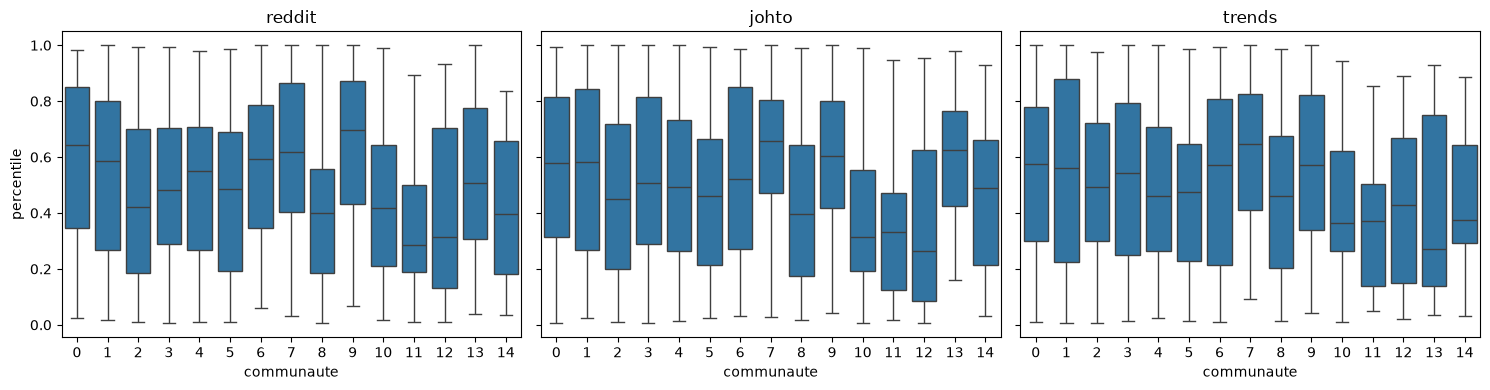

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, s in zip(axes, ["reddit", "johto", "trends"]):
    sns.boxplot(data=dp, x="communaute", y=s, ax=ax)
    ax.set_title(s); ax.set_ylabel("percentile")
plt.tight_layout(); plt.show()

### Ce qu'on a fait et pourquoi

**1. Louvain pour trouver les communautés.** On cherche des groupes de Pokémon très reliés entre eux et peu reliés au reste. Louvain fait ça en maximisant la **modularité** (vu au TP3/TP4), il est rapide, et il n'oblige pas à choisir le nombre de groupes à l'avance, contrairement à un k-means. On l'a fait **pondéré** par la similarité, pour qu'une arête entre deux quasi-jumeaux compte plus qu'une arête « limite ».

**2. Tester la stabilité avec plusieurs graines.** Louvain a une part de hasard. On l'a relancé avec 10 graines et on a comparé les découpages avec l'**ARI** (adjusted Rand index), qui mesure si deux découpages mettent les mêmes Pokémon ensemble (1 = identiques, 0 = pas mieux que le hasard). Comme les découpages se ressemblaient bien, on a gardé la graine 0 pour que ce soit reproductible.

**3. Comparer la modularité à celle d'un graphe aléatoire.** Même un graphe aléatoire a une modularité au-dessus de 0 quand on le découpe au mieux. Pour dire que nos communautés sont « réelles », on compare à la modularité de Louvain sur le graphe aléatoire de même taille.

**4. Décrire les communautés avec un tableau.** Pour chaque communauté, on a regardé les types, la couleur et la forme qui dominent, plus quelques exemples. C'est ce qui nous permet de leur donner un sens (« bleu · Eau », « carapaces »…), sinon ce seraient juste des numéros.

**5. Kruskal-Wallis pour comparer la popularité entre communautés.** On a plus de deux groupes et des percentiles qui ne sont pas normaux, donc on a pris Kruskal-Wallis plutôt qu'une ANOVA. On l'a fait aussi sur les **résidus** du notebook 05 : si l'écart entre communautés disparaît sur les résidus, c'est qu'il passait par les effets déjà connus (type, stade…) et pas par la communauté elle-même. Les boîtes à moustaches par communauté montrent la même chose en image, avec tout l'étalement.

**6. Le percentile dans la génération pour toutes les sources.** Au début on avait le percentile global pour Reddit et Google. Mais les générations récentes sont moins aimées, et les communautés n'ont pas toutes la même génération moyenne : avec un percentile global, on aurait pu attribuer à la communauté un effet qui vient de la génération. On a donc pris le percentile dans la génération partout, comme dans les notebooks 04 et 06. Les résultats sont restés les mêmes, et même un peu plus nets sur Google.

**7. La correction de Holm.** On fait 6 tests de Kruskal-Wallis. Au seuil de 5 %, il y a des chances qu'un test sorte significatif par hasard. La correction de Holm (comme au notebook 04) en tient compte. Ici, elle ne change rien pour les sources, mais elle fait tomber le seul résidu qui restait (le Johto Times).

## 4. Centralités et popularité

Pour chaque Pokémon, on calcule (comme au TP3) :
- le **degré** : nombre de voisins. Un Pokémon de fort degré ressemble à beaucoup d'autres (il est « banal ») ; un Pokémon de faible degré n'est le proche voisin de presque personne (il est « original ») ;
- la **similarité moyenne** à ses k voisins : plus elle est basse, plus le Pokémon est isolé dans l'espace des vecteurs ;
- l'**intermédiarité** (betweenness) : est-il sur beaucoup de plus courts chemins, comme un pont entre groupes ;
- la **proximité** (closeness) : est-il proche de tout le monde en moyenne ;
- le **coefficient de clustering** local : ses voisins sont-ils voisins entre eux.

Puis la corrélation de Spearman de chaque centralité avec chaque source de popularité.

In [16]:
cent = pd.DataFrame({
    "degre": dict(G.degree()),
    "similarite_voisins": {n: np.mean([G[n][v]["weight"] for v in G[n]]) for n in G},
    "intermediarite": nx.betweenness_centrality(G, seed=SEED),
    "proximite": nx.closeness_centrality(G),
    "clustering": nx.clustering(G),
})
# pour l'originalité « pure », la similarité aux k plus proches voisins (avant symétrisation)
cent["sim_k_voisins"] = pd.Series(1 - dist[:, 1:K + 1].mean(axis=1), index=noeuds)
cent.describe().round(3)

,degre,similarite_voisins,intermediarite,proximite,clustering,sim_k_voisins
count,1025.000,1025.000,1025.000,1025.000,1025.000,1025.000
mean,13.692,0.608,0.003,0.270,0.326,0.639
std,3.950,0.060,0.002,0.013,0.112,0.082
min,10.000,0.424,0.000,0.222,0.067,0.424
25%,11.000,0.570,0.001,0.263,0.244,0.581
50%,12.000,0.614,0.002,0.271,0.317,0.640
75%,15.000,0.651,0.003,0.278,0.385,0.696
max,31.000,0.743,0.011,0.305,0.800,0.856


La similarité moyenne d'un Pokémon à ses 10 plus proches voisins va de 0,43 (très à part) à 0,86 (il a des quasi-jumeaux).

In [17]:
lignes = []
for c in cent.columns:
    for s in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
        v = cent[[c]].join(dp[s]).dropna()
        rho, p = spearmanr(v[c], v[s])
        lignes.append({"centralite": c, "source": s, "rho": rho, "p": p})
res_c = pd.DataFrame(lignes)
# 36 tests (6 centralités x 6 mesures) : correction de Holm sur l'ensemble du tableau
res_c["p_holm"] = multipletests(res_c["p"], method="holm")[1]
print("significatifs avant correction :", (res_c.p < 0.05).sum(), "| après Holm :", (res_c.p_holm < 0.05).sum())
# une étoile = significatif après la correction de Holm
tab = res_c.assign(txt=res_c.rho.round(2).astype(str) + np.where(res_c.p_holm < 0.05, " *", "")).pivot(index="centralite", columns="source", values="txt")
tab[["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]]

significatifs avant correction : 5 | après Holm : 4


source,reddit,johto,trends,resid_reddit,resid_johto,resid_trends
centralite,,,,,,
clustering,-0.04,-0.04,-0.12 *,-0.03,0.0,-0.05
degre,-0.0,0.05,0.11 *,-0.04,0.0,0.03
intermediarite,-0.02,-0.0,0.11 *,-0.02,-0.02,0.04
proximite,-0.01,0.01,0.15 *,0.01,-0.02,0.07
sim_k_voisins,-0.01,0.04,0.05,-0.03,0.02,0.01
similarite_voisins,-0.01,0.02,0.03,-0.02,0.02,-0.0


Les centralités ne sont **presque pas liées à la popularité** : tous les rho sont entre -0,12 et 0,15. Sur 36 tests, 5 sont significatifs au seuil de 5 %, et 4 tiennent après la **correction de Holm**, tous sur **Google Trends** : la proximité (0,15), le degré et l'intermédiarité (0,11), et le clustering (-0,12). Un Pokémon au « centre » du réseau est donc un peu plus cherché sur Google, mais l'effet est faible, et il disparaît sur les résidus du notebook 05. Dans les **sondages, rien n'est significatif**, ni avant ni après correction. Être un Pokémon « original » ou « banal » dans ce réseau ne rend ni plus ni moins populaire.

In [18]:
# les plus « originaux » (similarité la plus basse à leurs k voisins) et les plus « banals »
o = cent.join(table[["nom_fr"]]).join(dp[["reddit", "johto", "trends"]]).sort_values("sim_k_voisins")
print("Les plus originaux :"); display(o.head(10)[["nom_fr", "sim_k_voisins", "degre", "reddit", "johto", "trends"]].round(2))
print("Les plus banals :"); display(o.tail(10)[["nom_fr", "sim_k_voisins", "degre", "reddit", "johto", "trends"]].round(2))

Les plus originaux :


,nom_fr,sim_k_voisins,degre,reddit,johto,trends
618,Limonde,0.42,10,0.69,0.27,0.72
101,Électrode,0.44,10,0.11,0.20,NaN
701,Brutalibré,0.45,10,0.92,0.83,0.79
987,Flotte-Mèche,0.45,10,NaN,0.77,0.68
617,Limaspeed,0.45,10,0.59,0.18,0.13
790,Cosmovum,0.45,10,0.03,0.07,0.50
752,Tarenbulle,0.46,10,0.79,0.69,0.14
337,Séléroc,0.46,10,0.21,0.36,0.35
446,Goinfrex,0.46,10,0.66,0.62,0.57
45,Rafflesia,0.46,10,0.62,0.67,0.21


Les plus banals :


,nom_fr,sim_k_voisins,degre,reddit,johto,trends
631,Aflamanoir,0.82,24,0.35,0.13,0.21
396,Étourmi,0.82,25,0.35,0.31,0.80
126,Magmar,0.83,23,0.43,0.30,0.54
467,Maganon,0.83,27,0.49,0.36,0.31
495,Vipélierre,0.83,21,0.87,0.89,0.91
252,Arcko,0.84,23,0.87,0.76,0.73
810,Ouistempo,0.84,22,NaN,0.73,0.75
506,Ponchiot,0.85,27,0.19,0.66,0.47
734,Manglouton,0.85,26,0.01,0.02,0.16
504,Ratentif,0.86,26,0.03,0.05,NaN


Les plus originaux sont des Pokémon au design atypique (Limonde, Électrode, Brutalibré, Flotte-Mèche, Limaspeed, Cosmovum, Rafflesia…), et leur popularité est très variable (Cosmovum est tout en bas, Brutalibré et Rafflesia plutôt aimés). Les plus banals sont surtout des stades 1 « petit mammifère » ou Feu (Ratentif, Ponchiot, Manglouton, Ouistempo, Arcko, Magmar) : là aussi on trouve des Pokémon très aimés (Arcko) et très peu aimés (Ratentif, Manglouton).

In [19]:
# l'originalité est-elle liée aux effets attendus ? (les légendaires sont peut-être juste plus « à part »)
o2 = cent[["sim_k_voisins", "degre"]].join(table[["legendaire", "fabuleux", "stade_categorie", "generation"]])
display(o2.groupby("stade_categorie")[["sim_k_voisins", "degre"]].mean().round(3))
display(o2.groupby("legendaire")[["sim_k_voisins", "degre"]].mean().round(3))
display(o2.groupby("generation")[["sim_k_voisins", "degre"]].mean().round(3))

,sim_k_voisins,degre
stade_categorie,,
sans évolution,0.620,13.816
stade 1,0.659,14.406
stade 2,0.629,12.793
stade 3,0.646,14.174


,sim_k_voisins,degre
legendaire,,
False,0.639,13.535
True,0.650,15.803


,sim_k_voisins,degre
generation,,
1,0.655,13.967
2,0.648,13.690
3,0.632,13.296
4,0.647,14.131
5,0.637,13.532
6,0.639,13.403
7,0.619,13.955
8,0.635,13.885
9,0.637,13.433


L'originalité ne dépend presque pas du stade, de la génération ou du statut de légendaire : les moyennes sont toutes très proches (0,62 à 0,66). Les légendaires ont même un peu plus de voisins (15,8 contre 13,5).

### Ce qu'on a fait et pourquoi

**1. Plusieurs centralités, parce qu'elles ne disent pas la même chose (TP3).** Le **degré** dit si un Pokémon ressemble à beaucoup d'autres (banal) ou à presque personne (original). La **similarité à ses voisins** dit s'il a des quasi-jumeaux ou s'il est isolé. L'**intermédiarité** dit s'il sert de pont entre des groupes, la **proximité** s'il est au « centre » du réseau, et le **clustering** si ses voisins se ressemblent entre eux. Comme on ne savait pas à l'avance laquelle pourrait jouer sur la popularité, on les a toutes testées.

**2. La similarité aux k voisins « avant symétrisation ».** Dans le graphe, un Pokémon peut gagner des voisins parce que d'autres l'ont choisi. Pour mesurer l'originalité « pure », on a pris la similarité moyenne à ses 10 plus proches voisins à lui, directement depuis les distances.

**3. Spearman avec la popularité, sur les sources et sur les résidus.** Spearman, parce que les centralités sont très asymétriques (l'intermédiarité surtout) et que la popularité est en percentile. Les résidus du notebook 05 servent à vérifier qu'un lien éventuel ne vient pas juste du type ou du stade. On a mis une étoile sur les corrélations significatives pour lire le tableau plus vite.

**4. La correction de Holm sur tout le tableau.** 6 centralités × 6 mesures, ça fait 36 tests : au seuil de 5 %, on s'attend à en trouver un ou deux « significatifs » par hasard. On a donc corrigé avec Holm sur les 36 tests en même temps (comme dans le notebook 04), et l'étoile veut dire « significatif après correction ». Avant, on en avait un de plus (la proximité avec le résidu Google) : il ne tient pas.

**5. Regarder les plus originaux et les plus banals.** Un coefficient proche de 0 peut cacher des choses. En listant les Pokémon aux deux extrêmes avec leur popularité, on voit concrètement qu'il y a des aimés et des pas aimés des deux côtés.

**6. Vérifier si l'originalité dépend du stade, de la génération ou des légendaires.** On pouvait penser que les légendaires sont « à part » par nature. On a donc comparé l'originalité moyenne par groupe pour voir si elle ne mesurait pas juste ça.

## 5. Les Pokémon populaires sont-ils voisins de Pokémon populaires ?

C'est l'**assortativité** : si on prend chaque arête, est-ce que les deux bouts ont une popularité proche ? On calcule le coefficient d'assortativité numérique de networkx pour chaque source (sur les Pokémon qui ont une valeur). Pour savoir si la valeur obtenue est grande, on la compare à ce qu'on obtient en **mélangeant la popularité au hasard** entre les Pokémon (test de permutation, 200 tirages). Comme ailleurs, la popularité est en percentile dans la génération.

In [20]:
def assortativite(G, valeurs):
    H = G.subgraph(valeurs.dropna().index).copy()
    nx.set_node_attributes(H, valeurs.dropna().to_dict(), "x")
    return nx.numeric_assortativity_coefficient(H, "x")

N_PERM = 200
rng = np.random.default_rng(SEED)
lignes = []
for s in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
    v = dp[s].dropna()
    r_obs = assortativite(G, v)
    r_perm = [assortativite(G, pd.Series(rng.permutation(v.values), index=v.index)) for _ in range(N_PERM)]
    lignes.append({"source": s, "assortativite": r_obs, "perm_moyenne": np.mean(r_perm), "perm_max": np.max(r_perm),
                   "p_permutation": (np.sum(np.array(r_perm) >= r_obs) + 1) / (N_PERM + 1)})
assort = pd.DataFrame(lignes)
assort.set_index("source").round(3)

,assortativite,perm_moyenne,perm_max,p_permutation
source,,,,
reddit,0.156,-0.001,0.039,0.005
johto,0.179,-0.001,0.035,0.005
trends,0.126,-0.001,0.028,0.005
resid_reddit,0.021,-0.001,0.049,0.090
resid_johto,0.045,-0.001,0.028,0.005
resid_trends,0.014,-0.001,0.029,0.114


En revanche, les Pokémon populaires **sont plutôt voisins de Pokémon populaires** : l'assortativité vaut 0,16 (Reddit), 0,18 (Johto Times) et 0,13 (Google). C'est faible, mais bien au-dessus de ce que donne un mélange au hasard (jamais plus de 0,04 en 200 tirages, p = 0,005, le plus petit possible avec 200 tirages).

Sur les résidus du notebook 05, l'assortativité tombe à 0,01-0,05, et elle n'est plus significative que pour le Johto Times (0,05, p = 0,005) ; sur Reddit (p = 0,09) et Google (p = 0,11), on ne peut plus la distinguer du hasard. Donc la ressemblance entre voisins populaires vient presque entièrement des effets attendus (même type, même position dans la lignée…).

reddit  rho = 0.345  p = 4.3e-24  (n = 809)
johto   rho = 0.420  p = 4.2e-45  (n = 1025)
trends  rho = 0.313  p = 4e-24  (n = 997)


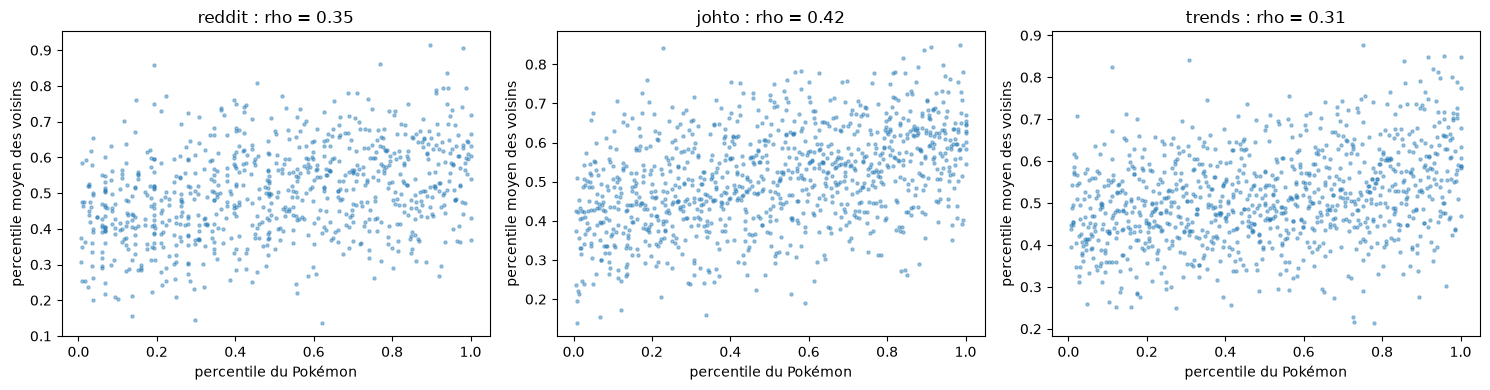

In [21]:
# version plus parlante : la popularité d'un Pokémon contre la popularité moyenne de ses voisins
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s in zip(axes, ["reddit", "johto", "trends"]):
    v = dp[s]
    moy_v = pd.Series({n: v.reindex(list(G[n])).mean() for n in G})
    w = pd.DataFrame({"soi": v, "voisins": moy_v}).dropna()
    ax.scatter(w.soi, w.voisins, s=5, alpha=.4)
    rho, p = spearmanr(w.soi, w.voisins)
    ax.set_title(f"{s} : rho = {rho:.2f}")
    print(f"{s:7s} rho = {rho:.3f}  p = {p:.2g}  (n = {len(w)})")
    ax.set_xlabel("percentile du Pokémon"); ax.set_ylabel("percentile moyen des voisins")
plt.tight_layout(); plt.show()

Avec la popularité moyenne des voisins, on voit la même chose : rho = 0,35 (Reddit), 0,42 (Johto Times) et 0,31 (Google), tous très significatifs. Le nuage reste très dispersé : avoir des voisins populaires ne garantit rien.

### Ce qu'on a fait et pourquoi

**1. L'assortativité.** La question « est-ce que les populaires sont voisins de populaires ? » se mesure avec le coefficient d'assortativité numérique : pour toutes les arêtes, on regarde si les deux bouts ont une popularité proche. C'est la version « réseau » d'une corrélation entre voisins.

**2. Un test par permutation plutôt qu'une p-valeur toute faite.** On ne sait pas bien quelle valeur l'assortativité prendrait « par hasard » sur un graphe comme le nôtre. Du coup, on a mélangé 200 fois la popularité entre les Pokémon (le graphe ne bouge pas) et recalculé l'assortativité à chaque fois. Si la vraie valeur est au-dessus de presque tous les tirages, ce n'est pas le hasard. C'est simple à comprendre et ça ne suppose rien sur la loi des données.

**3. Refaire le test sur les résidus.** Deux Pokémon voisins ont souvent le même type ou le même stade. Sur les résidus du notebook 05, ces effets sont retirés : si l'assortativité baisse beaucoup, c'est qu'elle venait surtout de là.

**4. Le nuage « popularité du Pokémon / popularité moyenne de ses voisins ».** Le coefficient d'assortativité est un peu abstrait. Ce nuage montre la même idée de façon plus parlante, et surtout il montre la **dispersion** : même avec un lien significatif, avoir des voisins populaires ne garantit rien.

## 6. Pokémon of the Year 2020, en quatrième source

Pokémon of the Year est le plus gros vote qu'on ait (plus de 6,6 millions de votes), mais il ne se traite pas comme les autres : The Pokémon Company n'a publié que le **top 30 de chaque génération** (n° 1 à 890). Pour chaque Pokémon, on sait juste s'il est **publié ou non**.

Le piège, c'est celui qu'on a vu dans le notebook 06 : la chance d'être publié vaut à peu près **30 / nombre de Pokémon de la génération**. Elle est de 20 % pour la génération 1 (151 Pokémon) et de 42 % pour la génération 6 (72 Pokémon). Si on comparait directement la part de publiés entre communautés, une communauté avec beaucoup de Pokémon de la génération 6 aurait l'air plus aimée sans l'être.

On compare donc, pour chaque communauté, le nombre de publiés au nombre **attendu si seule la génération comptait** (la somme, sur ses Pokémon, de la part de publiés de leur génération).

In [22]:
# seuls les n° 1 à 890 pouvaient être votés en 2020, et on ne connaît que le top 30 de chaque génération
votables = table.loc[table.index <= 890, ["generation"]].assign(publie=table["poty_votes"].notna().astype(int)).join(comm)
# la chance d'être publié si seule la génération comptait : nombre de publiés / nombre de votables de la génération
votables["attendu"] = votables.groupby("generation")["publie"].transform("mean")
poty_comm = votables.groupby("communaute").agg(n=("publie", "size"), publies=("publie", "sum"), attendus=("attendu", "sum"))
poty_comm["part_publiee"] = poty_comm.publies / poty_comm.n
poty_comm["part_attendue"] = poty_comm.attendus / poty_comm.n
poty_comm["rapport"] = poty_comm.publies / poty_comm.attendus   # > 1 : plus de publiés que ce que la génération prévoit
print(len(votables), "Pokémon votables,", votables.publie.sum(), "publiés")
poty_comm.round(2)

890 Pokémon votables, 240 publiés


,n,publies,attendus,part_publiee,part_attendue,rapport
communaute,,,,,,
0,96,32,26.13,0.33,0.27,1.22
1,94,37,25.45,0.39,0.27,1.45
2,93,24,25.22,0.26,0.27,0.95
3,83,28,24.29,0.34,0.29,1.15
4,70,19,17.97,0.27,0.26,1.06
5,82,11,22.00,0.13,0.27,0.50
6,79,25,21.62,0.32,0.27,1.16
7,62,22,15.77,0.35,0.25,1.40
8,49,7,13.67,0.14,0.28,0.51


Les communautés ont presque toutes la même part attendue (entre 25 % et 29 %) : comme on l'avait vu, aucune communauté n'est une génération. Mais les parts **publiées** vont de 6 % à 39 %. On retrouve le même ordre que dans les sondages : la bleue/Eau (1, 1,45 fois plus de publiés que prévu), la jaune/Électrik (7, ×1,40) et la noire (9, ×1,34) en haut ; les carapaces (11, ×0,25), les poissons (12, ×0,38), les marron/quadrupèdes (5, ×0,50), les roses (8) et les oiseaux (10) en bas.

Pour savoir si ces écarts peuvent venir du hasard, on fait un test par permutation : on mélange « publié / pas publié » **à l'intérieur de chaque génération** (on garde donc 30 publiés par génération, comme dans le vrai vote), et on regarde l'écart total entre publiés et attendus (la statistique du khi-deux).

In [23]:
# test : on mélange « publié / pas publié » au hasard, mais à l'intérieur de chaque génération,
# pour garder exactement 30 publiés par génération (comme dans le vrai vote)
N_PERM_POTY = 2000
rng = np.random.default_rng(SEED)
gen_idx = [np.flatnonzero(votables.generation.values == g) for g in sorted(votables.generation.unique())]
def melange_dans_gen(x):
    x = x.copy()
    for ix in gen_idx:
        x[ix] = rng.permutation(x[ix])
    return x
codes_comm = votables.communaute.values
att = poty_comm.attendus.values
def publies_par_comm(x):
    return np.bincount(codes_comm, weights=x, minlength=len(att))
def ecart(obs):   # statistique du khi-deux : écart total entre publiés observés et attendus
    return (((obs - att) ** 2) / att).sum()
obs = publies_par_comm(votables.publie.values.astype(float))
perm = np.array([publies_par_comm(melange_dans_gen(votables.publie.values.astype(float))) for _ in range(N_PERM_POTY)])
chi_perm = np.array([ecart(p) for p in perm])
p_global = (np.sum(chi_perm >= ecart(obs)) + 1) / (N_PERM_POTY + 1)
print(f"écart observé = {ecart(obs):.1f} | au hasard : moyenne {chi_perm.mean():.1f}, max {chi_perm.max():.1f} | p = {p_global:.4f}")
# communauté par communauté (test bilatéral), avec Holm sur les 15 communautés
plus = (np.sum(perm >= obs, axis=0) + 1) / (N_PERM_POTY + 1)
moins = (np.sum(perm <= obs, axis=0) + 1) / (N_PERM_POTY + 1)
poty_comm["p_valeur"] = np.minimum(1, 2 * np.minimum(plus, moins))
poty_comm["p_holm"] = multipletests(poty_comm["p_valeur"], method="holm")[1]
poty_comm.sort_values("rapport").round(3)

écart observé = 30.3 | au hasard : moyenne 10.0, max 27.1 | p = 0.0005


,n,publies,attendus,part_publiee,part_attendue,rapport,p_valeur,p_holm
communaute,,,,,,,,
11,33,2,8.144,0.061,0.247,0.246,0.010,0.130
12,31,3,8.009,0.097,0.258,0.375,0.040,0.480
5,82,11,22.002,0.134,0.268,0.500,0.001,0.015
8,49,7,13.669,0.143,0.279,0.512,0.040,0.480
10,40,6,10.937,0.150,0.273,0.549,0.083,0.830
14,17,4,4.308,0.235,0.253,0.928,1.000,1.000
2,93,24,25.222,0.258,0.271,0.952,0.868,1.000
13,20,5,5.246,0.250,0.262,0.953,1.000,1.000
4,70,19,17.973,0.271,0.257,1.057,0.850,1.000


L'écart observé (30,3) est plus grand que dans les 2 000 mélanges (au maximum 27,1) : **les communautés n'ont pas la même chance d'être publiées**, à génération égale (p = 0,0005). Communauté par communauté, avec la correction de Holm sur les 15, seule une tient : les **marron/quadrupèdes** (5) ont deux fois moins de publiés que prévu (11 au lieu de 22, p corrigé = 0,015). La bleue/Eau (1, 37 au lieu de 25) et les carapaces (11, 2 au lieu de 8) sont significatives avant correction, mais pas après.

Ensuite, l'assortativité : un Pokémon publié a-t-il plus souvent des voisins publiés ?

In [24]:
# assortativité : un Pokémon publié a-t-il des voisins publiés ?
publie = votables["publie"].astype(float)
r_obs = assortativite(G, publie)
rng = np.random.default_rng(SEED)
pos_v = votables.index
r_libre = [assortativite(G, pd.Series(rng.permutation(publie.values), index=pos_v)) for _ in range(N_PERM)]
r_gen = [assortativite(G, pd.Series(melange_dans_gen(publie.values), index=pos_v)) for _ in range(N_PERM)]
assort_poty = pd.DataFrame({
    "mélange": ["libre (tous les Pokémon)", "dans la génération"],
    "assortativite": [r_obs, r_obs], "perm_moyenne": [np.mean(r_libre), np.mean(r_gen)],
    "perm_max": [np.max(r_libre), np.max(r_gen)],
    "p_permutation": [(np.sum(np.array(r_libre) >= r_obs) + 1) / (N_PERM + 1), (np.sum(np.array(r_gen) >= r_obs) + 1) / (N_PERM + 1)]})
assort_poty.round(3)

,mélange,assortativite,perm_moyenne,perm_max,p_permutation
0,libre (tous les Pokémon),0.105,-0.0,0.040,0.005
1,dans la génération,0.105,0.0,0.044,0.005


Oui : l'assortativité de « publié » vaut **0,10**, au-dessus de tous les mélanges, qu'on mélange librement (max 0,04) ou dans la génération (max 0,04), avec p = 0,005 dans les deux cas. Le mélange dans la génération ne change presque rien, ce qui confirme que l'effet ne vient pas de la taille des générations.

C'est le même ordre de grandeur que pour Google (0,13) et un peu moins que les sondages (0,16-0,18). Pokémon of the Year raconte donc la même chose que les trois autres sources : **les familles de couleur et de forme n'ont pas la même popularité, et les populaires ont un peu plus de voisins populaires.**

Une limite : pour les sondages, on a pu vérifier sur les résidus du notebook 05 que ces effets passaient surtout par le type. Pour Pokémon of the Year, on n'a pas exporté de résidu du modèle logistique du notebook 05, donc on ne l'a pas vérifié ici. Vu les communautés en tête (Eau, Électrik), c'est probablement la même chose.

### Ce qu'on a fait et pourquoi

**1. Garder Pokémon of the Year à part.** On n'a que le top 30 de chaque génération : pas de classement complet, juste « publié ou non ». On ne pouvait donc pas le mettre dans le Kruskal-Wallis ou les corrélations avec les percentiles, comme les trois autres sources.

**2. Comparer à ce que la génération prévoit.** Dans le notebook 06, on a écarté Pokémon of the Year du test design/nostalgie parce que la part publiée vaut juste 30 / taille de la génération. Ici, le problème est le même : on ne compare pas les parts publiées entre elles, mais à la part attendue vu les générations de la communauté.

**3. Un test par permutation dans la génération.** Pour savoir quel écart on aurait par hasard, on a mélangé « publié / pas publié » à l'intérieur de chaque génération. Ça garde exactement la contrainte du vrai vote (30 publiés par génération) et ne suppose rien sur la loi des données. On a pris 2 000 tirages, plus que les 200 de la section 5, pour pouvoir corriger 15 p-valeurs avec Holm.

**4. L'assortativité avec deux mélanges.** Un mélange libre et un mélange dans la génération : si les deux donnent la même chose, l'effet ne vient pas de la taille des générations.

## 7. Et sans la couleur officielle ?

En section 3, on a vu que les communautés suivent surtout la **couleur officielle** de PokéAPI (une seule couleur par Pokémon, comme « jaune » ou « rose »). C'est une étiquette grossière, et elle fait double emploi avec les couleurs de l'image du notebook 03. On l'a gardée (section 1), mais on veut savoir **ce que ce choix change** : on refait le réseau sans ce bloc (les 5 autres blocs gardent chacun le même poids), puis on relance tous les tests de popularité.

In [25]:
# même construction qu'en section 1 et 2, sans le bloc couleur officielle (5 blocs, toujours le même poids chacun)
parties_sc = []
for nom, b in blocs.items():
    if nom == "couleur_off":
        continue
    z = StandardScaler().fit_transform(b.astype(float))
    parties_sc.append(pd.DataFrame(z / np.sqrt(b.shape[1]), index=b.index, columns=[f"{nom}:{c}" for c in b.columns]))
X_sc = pd.concat(parties_sc, axis=1).loc[table.index]
dist_sc, idx_sc = NearestNeighbors(metric="cosine").fit(X_sc.values).kneighbors(X_sc.values, n_neighbors=K + 1)
G_sc = nx.Graph()
G_sc.add_nodes_from(noeuds)
for i in range(len(noeuds)):
    for j, dd in zip(idx_sc[i, 1:], dist_sc[i, 1:]):
        G_sc.add_edge(noeuds[i], noeuds[j], weight=1 - dd)
communautes_sc = louvain_communities(G_sc, weight="weight", seed=SEED)
comm_sc = etiquettes(communautes_sc).rename("communaute")
aretes_communes = len({frozenset(e) for e in G.edges()} & {frozenset(e) for e in G_sc.edges()}) / G.number_of_edges()
print(f"{X_sc.shape[1]} colonnes | {G_sc.number_of_edges()} arêtes, dont {aretes_communes:.0%} déjà dans le graphe complet")
print(f"{len(communautes_sc)} communautés, modularité = {modularity(G_sc, communautes_sc, weight='weight'):.3f}")
print(f"accord avec les communautés du graphe complet (ARI) : {adjusted_rand_score(comm, comm_sc.loc[comm.index]):.2f}")

46 colonnes | 6993 arêtes, dont 55% déjà dans le graphe complet
18 communautés, modularité = 0.676
accord avec les communautés du graphe complet (ARI) : 0.19


In [26]:
# qui est dans les nouvelles communautés ?
d_sc = table.join(comm_sc)
d_sc.groupby("communaute").agg(
    n=("nom_fr", "size"),
    types=("type1", lambda s: top(pd.concat([s, d_sc.loc[s.index, "type2"].dropna()]))),
    couleur=("couleur", top),
    forme=("forme_corps", lambda s: top(s, 2)),
    exemples=("nom_fr", lambda s: ", ".join(s.loc[d_sc.loc[s.index, "total_stats"].sort_values(ascending=False).index[:4]])))

,n,types,couleur,forme,exemples
communaute,,,,,
0,133,"fire 28%, electric 10%, fighting 9%","red 32%, yellow 25%, brown 19%","quadruped 44%, upright 38%","Arceus, Xerneas, Solgaleo, Ho-Oh"
1,112,"normal 37%, electric 16%, dark 14%","brown 29%, gray 12%, purple 12%","quadruped 63%, upright 29%","Luxray, Dogrino, Démolosse, Kangourex"
2,111,"psychic 24%, fairy 23%, grass 9%","pink 20%, purple 17%, white 12%","ball 41%, humanoid 39%","Mew, Jirachi, Celebi, Meloetta"
3,78,"ground 26%, rock 22%, steel 12%","brown 29%, gray 26%, blue 15%","upright 33%, quadruped 32%","Monaflèmit, Tyranocif, Melmetal, Regirock"
4,78,"ice 24%, dragon 21%, water 9%","blue 29%, white 24%, purple 15%","upright 42%, quadruped 23%","Éthernatos, Lugia, Zekrom, Reshiram"
5,63,"flying 49%, normal 20%, psychic 4%","brown 24%, black 14%, blue 14%",wings 100%,"Favianos, Bruyverne, Ptéra, Gueriaigle"
6,57,"grass 67%, poison 11%, flying 5%","green 77%, pink 5%, brown 5%","humanoid 40%, upright 33%","Vert-de-Fer, Viridium, Ogerpon, Miascarade"
7,53,"fighting 55%, dark 12%, poison 5%","gray 28%, blue 15%, white 15%","humanoid 57%, upright 38%","Darkrai, Marshadow, Zarude, Garde-de-Fer"
8,48,"ghost 17%, psychic 13%, fairy 13%","purple 17%, black 17%, white 15%",arms 100%,"Démétéros, Hoopa, Diancie, Necrozma"


Sans la couleur officielle, le réseau change beaucoup : seulement **55 % des arêtes** sont les mêmes, Louvain trouve **18 communautés** au lieu de 15 (modularité 0,68 au lieu de 0,71), et l'accord avec les communautés de départ est faible (**ARI = 0,19**). Les familles de couleur disparaissent (la verte/Plante reste, parce que ses Pokémon sont presque tous de type Plante) : les nouvelles communautés suivent surtout **la forme du corps** (100 % « ailes », « bras », « poisson », « serpent », « blob », « tentacules »…) et **le type** (Feu, Combat, Sol/Roche, Glace/Dragon, Insecte).

Le choix de la couleur officielle change donc beaucoup **qui est avec qui**. La question, c'est de savoir s'il change aussi ce qu'on conclut sur la popularité.

In [27]:
# on refait les tests de popularité des sections 3 à 6 sur ce réseau, et on compare
mesures = ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]
dp_sc = dp.drop(columns="communaute").join(comm_sc)
kw_sc = pd.Series({c: kruskal(*[g[c].dropna() for _, g in dp_sc.groupby("communaute")])[1] for c in mesures})
kw_sc[:] = multipletests(kw_sc, method="holm")[1]
cent_sc = pd.DataFrame({"degre": dict(G_sc.degree()),
    "similarite_voisins": {n: np.mean([G_sc[n][v]["weight"] for v in G_sc[n]]) for n in G_sc},
    "intermediarite": nx.betweenness_centrality(G_sc, seed=SEED), "proximite": nx.closeness_centrality(G_sc),
    "clustering": nx.clustering(G_sc)})
cent_sc["sim_k_voisins"] = pd.Series(1 - dist_sc[:, 1:].mean(axis=1), index=noeuds)
rc = pd.DataFrame([{"centralite": c, "source": s, "rho": spearmanr(*cent_sc[[c]].join(dp[s]).dropna().T.values)[0],
                    "p": spearmanr(*cent_sc[[c]].join(dp[s]).dropna().T.values)[1]} for c in cent_sc for s in mesures])
rc["p_holm"] = multipletests(rc["p"], method="holm")[1]
print("centralités significatives après Holm, sans la couleur officielle :")
display(rc[rc.p_holm < 0.05].round(3))
rng = np.random.default_rng(SEED)
as_sc = {}
for s in mesures:
    v = dp[s].dropna()
    r_obs_sc = assortativite(G_sc, v)
    r_perm = [assortativite(G_sc, pd.Series(rng.permutation(v.values), index=v.index)) for _ in range(N_PERM)]
    as_sc[s] = (r_obs_sc, (np.sum(np.array(r_perm) >= r_obs_sc) + 1) / (N_PERM + 1))
# Pokémon of the Year : même test d'écart à la génération, sur les nouvelles communautés
cc_sc = comm_sc.loc[votables.index].values
att_sc = np.bincount(cc_sc, weights=votables.attendu.values)
obs_sc = np.bincount(cc_sc, weights=votables.publie.values.astype(float))
rng = np.random.default_rng(SEED)
chi_sc = [(((np.bincount(cc_sc, weights=melange_dans_gen(votables.publie.values.astype(float))) - att_sc) ** 2) / att_sc).sum()
          for _ in range(N_PERM_POTY)]
p_poty_sc = (np.sum(np.array(chi_sc) >= (((obs_sc - att_sc) ** 2) / att_sc).sum()) + 1) / (N_PERM_POTY + 1)

kw_avec = kw.set_index("mesure")["p_holm"]
asr = assort.set_index("source")
robustesse = pd.DataFrame(
    [{"mesure": "nombre de communautés", "avec_couleur": len(communautes), "sans_couleur": len(communautes_sc)},
     {"mesure": "modularité", "avec_couleur": modularity(G, communautes, weight="weight"), "sans_couleur": modularity(G_sc, communautes_sc, weight="weight")},
     {"mesure": "ARI avec le réseau complet", "avec_couleur": 1.0, "sans_couleur": adjusted_rand_score(comm, comm_sc.loc[comm.index])}]
    + [{"mesure": f"Kruskal-Wallis {s} (p Holm)", "avec_couleur": kw_avec[s], "sans_couleur": kw_sc[s]} for s in mesures]
    + [{"mesure": "Pokémon of the Year, écart à la génération (p)", "avec_couleur": p_global, "sans_couleur": p_poty_sc}]
    + [{"mesure": "centralités significatives après Holm (sur 36)", "avec_couleur": (res_c.p_holm < 0.05).sum(), "sans_couleur": (rc.p_holm < 0.05).sum()},
       {"mesure": "plus grand |rho| centralité", "avec_couleur": res_c.rho.abs().max(), "sans_couleur": rc.rho.abs().max()}]
    + [{"mesure": f"assortativité {s}", "avec_couleur": asr.loc[s, "assortativite"], "sans_couleur": as_sc[s][0]} for s in mesures]
    + [{"mesure": f"assortativité {s} (p)", "avec_couleur": asr.loc[s, "p_permutation"], "sans_couleur": as_sc[s][1]} for s in mesures])
robustesse.round(3)

centralités significatives après Holm, sans la couleur officielle :


,centralite,source,rho,p,p_holm
2,degre,trends,0.117,0.0,0.006
13,intermediarite,johto,0.113,0.0,0.008
14,intermediarite,trends,0.135,0.0,0.001
18,proximite,reddit,0.143,0.0,0.001
19,proximite,johto,0.156,0.0,0.000
20,proximite,trends,0.200,0.0,0.000
24,clustering,reddit,-0.178,0.0,0.000
25,clustering,johto,-0.183,0.0,0.000
26,clustering,trends,-0.189,0.0,0.000


,mesure,avec_couleur,sans_couleur
0,nombre de communautés,15.000,18.000
1,modularité,0.714,0.676
2,ARI avec le réseau complet,1.000,0.190
3,Kruskal-Wallis reddit (p Holm),0.000,0.000
4,Kruskal-Wallis johto (p Holm),0.000,0.000
5,Kruskal-Wallis trends (p Holm),0.002,0.000
6,Kruskal-Wallis resid_reddit (p Holm),0.301,0.929
7,Kruskal-Wallis resid_johto (p Holm),0.055,0.448
8,Kruskal-Wallis resid_trends (p Holm),0.567,0.929
9,"Pokémon of the Year, écart à la génération (p)",0.000,0.000


Sur la popularité, **les conclusions tiennent** :
- **les communautés** n'ont toujours pas la même popularité dans les trois sources (Kruskal-Wallis, p < 0,001 après Holm), et ça disparaît toujours sur les résidus du notebook 05 (même encore plus nettement : p corrigés de 0,45 à 0,93). Pokémon of the Year aussi garde un écart entre communautés à génération égale (p = 0,0005) ;
- **l'assortativité** est un peu plus forte (0,16 à 0,22 au lieu de 0,13 à 0,18), et sur les résidus elle reste au même niveau (seul le Johto Times reste significatif, à 0,05).

Une nuance sur les **centralités** : sans la couleur officielle, 9 liens tiennent après Holm au lieu de 4, et cette fois aussi dans les sondages. Les Pokémon dont les voisins sont reliés entre eux (clustering élevé) sont un peu moins aimés (rho ≈ -0,18 dans les trois sources), et ceux qui sont proches de tout le monde (proximité) un peu plus (0,14 à 0,20). Ces liens restent faibles (|rho| ≤ 0,20) et **aucun ne tient sur les résidus** : ils passent par les effets attendus, comme sur Google avec le réseau de départ. La conclusion « être original ou banal ne change rien à la popularité, une fois les effets attendus retirés » tient donc dans les deux réseaux, mais la phrase « les centralités ne sont liées à rien dans les sondages » dépend du choix de la couleur officielle.

**Décision** : on garde le réseau avec la couleur officielle, comme prévu en section 1, et on garde ce test pour montrer ce que coûte ce choix.

### Ce qu'on a fait et pourquoi

**1. Tester le choix plutôt que le discuter.** On hésitait sur la couleur officielle depuis la section 1. Plutôt que de changer d'avis, on a refait tout le réseau sans elle, avec exactement les mêmes réglages (k = 10, similarité cosinus, Louvain avec la graine 0), pour chiffrer ce qu'elle change.

**2. L'ARI pour comparer les communautés.** C'est la même mesure que pour la stabilité de Louvain (section 3). Là, on compare deux réseaux différents, pas deux graines : un ARI faible veut dire que les groupes ne sont plus les mêmes.

**3. Relancer tous les tests de popularité.** Si les familles changent, les conclusions pourraient changer aussi. On a refait le Kruskal-Wallis (avec Holm), les centralités (avec Holm sur les 36 tests), l'assortativité et le test Pokémon of the Year, et on a tout mis dans un seul tableau, avec et sans la couleur officielle.

**4. Garder la couleur officielle quand même.** Les conclusions ne changent pas, donc on garde le réseau de départ : ses communautés se lisent beaucoup plus facilement (une couleur ou une forme chacune), ce qui compte pour les montrer dans le dashboard.

## 8. node2vec et t-SNE

node2vec (TP4) : on fait des **marches aléatoires** dans le graphe, on les traite comme des « phrases » dont les « mots » sont les Pokémon, et **Word2Vec** apprend un vecteur par Pokémon de façon que ceux qui apparaissent dans les mêmes marches aient des vecteurs proches. On a fait les marches à la main (même fonction qu'au TP4).

Pour les réglages, on reste proche de ce qu'on a fait au TP4 :
- **p = q = 1** : des marches aléatoires classiques, sans favoriser ni le retour en arrière ni l'exploration au loin. On n'a pas de raison de préférer l'un ou l'autre ici ;
- **10 marches de 40 pas** par Pokémon : avec un degré moyen autour de 14, une marche de 40 pas a le temps de sortir du voisinage direct, et 10 marches suffisent pour que chaque Pokémon apparaisse souvent ;
- **vecteurs de dimension 16** : on n'a que 1 025 Pokémon, et on veut juste une carte en 2D derrière, donc pas besoin de grands vecteurs ;
- **fenêtre de 5** : Word2Vec considère que deux Pokémon à moins de 5 pas dans une marche sont « dans le même contexte ».

Ensuite, **t-SNE** projette ces vecteurs en 2D pour faire une carte. On garde la **perplexité par défaut (30)** : elle correspond à peu près au nombre de voisins qu'on regarde, et 30 c'est raisonnable pour 1 025 points (ni trop local, ni trop global). On mesure avec la **trustworthiness** si les voisins sur la carte sont bien des voisins dans l'espace d'origine (1 = parfait).

In [28]:
from gensim.models import Word2Vec

def marches_node2vec(G, n_marches=10, longueur=40, p=1.0, q=1.0, seed=0):
    rng = random.Random(seed)
    voisins_de = {u: list(G[u]) for u in G}
    noeuds_, marches = list(G), []
    for _ in range(n_marches):
        rng.shuffle(noeuds_)
        for depart in noeuds_:
            marche = [depart]
            while len(marche) < longueur:
                ns = voisins_de[marche[-1]]
                if len(marche) == 1:
                    marche.append(rng.choice(ns)); continue
                prec = marche[-2]
                poids = [1 / p if x == prec else 1 if G.has_edge(x, prec) else 1 / q for x in ns]
                marche.append(rng.choices(ns, weights=poids)[0])
            marches.append(marche)
    return marches

N2V_DIM, N2V_MARCHES, N2V_LONGUEUR, N2V_P, N2V_Q = 16, 10, 40, 1.0, 1.0
marches = marches_node2vec(G, N2V_MARCHES, N2V_LONGUEUR, N2V_P, N2V_Q, SEED)
phrases = [[str(n) for n in m] for m in marches]
w2v = Word2Vec(phrases, vector_size=N2V_DIM, window=5, min_count=0, sg=1, workers=1, seed=SEED, epochs=5)
N2V = np.array([w2v.wv[str(n)] for n in noeuds])
print(len(marches), "marches | vecteurs :", N2V.shape)

10250 marches | vecteurs : (1025, 16)


10 marches de 40 pas par Pokémon, soit 10 250 marches, et un vecteur de 16 dimensions par Pokémon.

In [29]:
# les voisins dans l'espace node2vec ressemblent-ils à ceux du graphe ?
from sklearn.metrics.pairwise import cosine_similarity
S = cosine_similarity(N2V)
pos = {n: i for i, n in enumerate(noeuds)}
for d in [6, 25, 94, 133, 448]:
    o = np.argsort(-S[pos[d]])[1:7]
    print(f"{table.loc[d, 'nom_fr']:12s} →", ", ".join(table.loc[noeuds[o], "nom_fr"]))

Dracaufeu    → Camérupt, Magmar, Pyroli, Maganon, Aflamanoir, Braségali
Pikachu      → Galvaran, Posipi, Pâtachiot, Voltoutou, Pohm, Miaouss
Ectoplasma   → Mentali, Groret, Salarsen, Wimessir, Avaltout, Mewtwo
Évoli        → Ponchiot, Manglouton, Fouinette, Keunotor, Goupix, Ratentif
Lucario      → Carchacrok, Pingoléon, Pondralugon, Coatox, Laggron, Carmache


Les voisins node2vec ressemblent à ceux du graphe, mais en un peu plus « large » : node2vec regarde aussi les voisins des voisins. Dracaufeu reste avec des Pokémon Feu (Camérupt, Magmar, Pyroli, Maganon…), Pikachu avec des Pokémon jaunes, surtout Électrik (Galvaran, Posipi, Pâtachiot, Voltoutou…), et Lucario se retrouve avec d'autres Pokémon bipèdes et combatifs (Carchacrok, Pingoléon, Coatox…).

In [30]:
TSNE_PERPLEXITE = 30
tsne_n2v = TSNE(n_components=2, perplexity=TSNE_PERPLEXITE, random_state=SEED, init="pca").fit_transform(N2V)
tsne_x = TSNE(n_components=2, perplexity=TSNE_PERPLEXITE, random_state=SEED, init="pca", metric="cosine").fit_transform(X.values)
pd.DataFrame({
    "trustworthiness (10 voisins)": [trustworthiness(N2V, tsne_n2v, n_neighbors=10), trustworthiness(X.values, tsne_x, n_neighbors=10, metric="cosine")],
}, index=["node2vec → t-SNE (vs node2vec)", "vecteurs → t-SNE direct (vs vecteurs)"]).round(3)

,trustworthiness (10 voisins)
node2vec → t-SNE (vs node2vec),0.992
vecteurs → t-SNE direct (vs vecteurs),0.967


Les deux cartes t-SNE préservent très bien les voisinages : trustworthiness de 0,99 pour node2vec → t-SNE et 0,97 pour le t-SNE direct sur les vecteurs. La perplexité de 30 convient donc, on n'a pas besoin d'en tester d'autres.

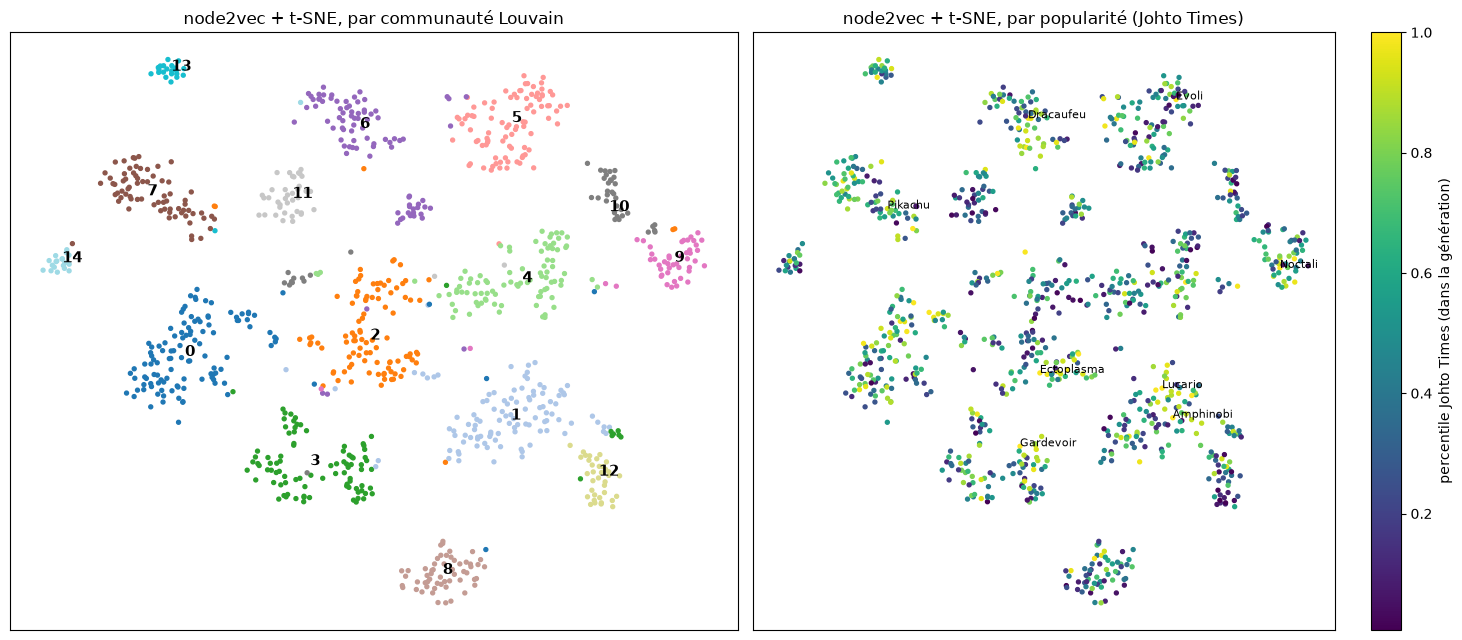

In [31]:
carte = pd.DataFrame(tsne_n2v, index=noeuds, columns=["x", "y"]).join(comm).join(dp[["johto", "reddit", "trends"]]).join(table[["nom_fr"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(carte.x, carte.y, c=carte.communaute, cmap="tab20", s=8)
for c, g in carte.groupby("communaute"):
    axes[0].text(g.x.median(), g.y.median(), str(c), fontsize=11, weight="bold")
axes[0].set_title("node2vec + t-SNE, par communauté Louvain")
sc = axes[1].scatter(carte.x, carte.y, c=carte.johto, cmap="viridis", s=8)
plt.colorbar(sc, ax=axes[1], label="percentile Johto Times (dans la génération)")
for n in [6, 25, 94, 133, 448, 197, 282, 658]:
    axes[1].annotate(table.loc[n, "nom_fr"], (carte.loc[n, "x"], carte.loc[n, "y"]), fontsize=8)
axes[1].set_title("node2vec + t-SNE, par popularité (Johto Times)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Sur la carte, les communautés Louvain forment des îlots bien séparés. Dans chaque îlot, la popularité est mélangée (des points clairs et foncés côte à côte), avec par endroits de petits groupes de Pokémon très aimés proches les uns des autres. Ça colle avec l'assortativité faible mais réelle qu'on a mesurée.

### Ce qu'on a fait et pourquoi

**1. node2vec pour passer du graphe à des vecteurs (TP4).** On ne peut pas dessiner directement un graphe de 1 025 nœuds et 7 000 arêtes de façon lisible. node2vec fait des marches aléatoires dans le graphe, les traite comme des phrases, et Word2Vec apprend un vecteur par Pokémon : deux Pokémon qui apparaissent souvent dans les mêmes marches ont des vecteurs proches. L'avantage par rapport aux vecteurs de départ, c'est qu'il tient compte de la **structure du réseau** (les voisins des voisins), pas seulement de la ressemblance directe.

**2. Les réglages.** p = q = 1 donne des marches aléatoires classiques : on n'avait pas de raison de favoriser le retour en arrière ou l'exploration au loin. 10 marches de 40 pas par Pokémon, pour que chacun apparaisse souvent et que les marches sortent du voisinage direct. Des vecteurs de dimension 16, parce qu'on n'a que 1 025 Pokémon et qu'on veut juste une carte derrière. On a gardé des réglages proches du TP4, et une graine fixe pour pouvoir refaire exactement le même résultat.

**3. Vérifier les voisins node2vec.** Comme pour le graphe, on a regardé les voisins de quelques Pokémon connus : si node2vec avait tout mélangé, la carte qui suit ne voudrait rien dire.

**4. t-SNE pour la carte en 2D.** On a choisi t-SNE plutôt qu'une PCA pour la carte, parce que t-SNE garde surtout les **voisinages** (qui est proche de qui), ce qui est exactement ce qui compte dans un réseau de ressemblance. Une PCA garde les grandes directions de variance, mais écrase souvent les petits groupes les uns sur les autres. On a gardé la perplexité par défaut (30), qui correspond à peu près au nombre de voisins regardés.

**5. Mesurer la qualité de la carte avec la trustworthiness.** Avec t-SNE, il faut vérifier que les voisins sur la carte sont bien des voisins dans l'espace de départ. La trustworthiness mesure ça (1 = parfait). On l'a calculée pour node2vec → t-SNE et pour un t-SNE direct sur les vecteurs, pour comparer les deux chemins.

**6. Deux cartes côte à côte.** La même carte colorée une fois par communauté Louvain et une fois par popularité. Ça permet de voir d'un coup d'œil si les communautés forment des îlots, et si la popularité se regroupe dans certains coins ou est mélangée partout. Quelques Pokémon connus sont annotés pour se repérer.

## 9. Export

In [32]:
noeuds_df = table[["nom_fr", "nom_en", "generation", "type1", "type2"]].join(comm).join(cent).join(
    pd.DataFrame(tsne_n2v, index=noeuds, columns=["tsne_x", "tsne_y"]))
noeuds_df.index.name = "dex"
aretes = pd.DataFrame([(u, v, w) for u, v, w in G.edges(data="weight")], columns=["source", "cible", "similarite"])
noeuds_df.to_csv(OUT / "reseau_noeuds.csv")
aretes.to_csv(OUT / "reseau_aretes.csv", index=False)
print(noeuds_df.shape, aretes.shape)

(1025, 14) (7017, 3)


Exports : 1 025 nœuds (communauté, centralités, coordonnées t-SNE) et 7 017 arêtes (avec la similarité), pour le graphe interactif dans Dash.

On exporte aussi les résultats intermédiaires pour pouvoir montrer la méthode dans le dashboard : l'effet de k, la comparaison avec le graphe aléatoire, les communautés et leur popularité, les tests et la stabilité de Louvain. Pour les communautés, on leur donne un petit nom d'après ce qu'on a vu dans le tableau de la section 3 (couleur ou forme qui domine).

In [33]:
# l'effet de k sur le graphe
effet_k.rename(columns={"degre moyen": "degre_moyen"})[["k", "composantes", "aretes", "degre_moyen"]].to_csv(OUT / "methode_07_k.csv", index=False)

# petit monde : notre graphe contre le graphe aléatoire de même taille
mod_reseau = modularity(G, communautes, weight="weight")
petit_monde = pd.DataFrame({
    "mesure": ["clustering", "chemin moyen", "diamètre", "modularité Louvain"],
    "reseau": [comparaison.loc["clustering moyen", "Pokémon (kNN)"], comparaison.loc["plus court chemin moyen (LCC)", "Pokémon (kNN)"],
               comparaison.loc["diamètre (LCC)", "Pokémon (kNN)"], mod_reseau],
    "aleatoire": [comparaison.loc["clustering moyen", "Aléatoire G(n,m)"], comparaison.loc["plus court chemin moyen (LCC)", "Aléatoire G(n,m)"],
                  comparaison.loc["diamètre (LCC)", "Aléatoire G(n,m)"], mod_rand]})
petit_monde.to_csv(OUT / "methode_07_petit_monde.csv", index=False)

# les communautés, avec un nom lisible et la popularité moyenne (mêmes mesures que plus haut)
# les numéros viennent de Louvain : si les données changent, la numérotation peut changer aussi.
# Les noms sont donnés d'après le tableau de la section 3 (couleur ou forme qui domine) : à relire si le contrôle ci-dessous échoue.
noms_comm = {0: "vert · Plante", 1: "bleu · Eau", 2: "violet · Poison/Spectre", 3: "blanc",
             4: "gris · Acier/Roche", 5: "marron · quadrupèdes", 6: "rouge · Feu", 7: "jaune · Électrik",
             8: "rose · Fée/Psy", 9: "noir", 10: "ailes", 11: "carapaces", 12: "poissons",
             13: "ailes d'insecte", 14: "pattes"}
assert set(noms_comm) == set(moy.index), "le nombre de communautés a changé : relire le tableau de la section 3 et renommer"
comm_df = moy[["n", "reddit", "johto", "trends"]].join(poty_comm[["part_publiee", "part_attendue"]]).rename(columns={"n": "taille"}).rename_axis("communaute").reset_index()
comm_df.insert(2, "nom", comm_df["communaute"].map(noms_comm))
comm_df.to_csv(OUT / "methode_07_communautes.csv", index=False)

# Kruskal-Wallis, centralités, assortativité
kw.to_csv(OUT / "methode_07_kruskal.csv", index=False)
res_c.rename(columns={"p": "p_valeur"}).to_csv(OUT / "methode_07_centralites.csv", index=False)
# pour Pokémon of the Year, l'assortativité est comparée aux mélanges dans la génération (section 6)
a_poty = assort_poty[assort_poty["mélange"] == "dans la génération"].assign(source="poty")
pd.concat([assort, a_poty]).rename(columns={"source": "mesure", "perm_max": "max_hasard", "p_permutation": "p_valeur"})[
    ["mesure", "assortativite", "max_hasard", "p_valeur"]].to_csv(OUT / "methode_07_assortativite.csv", index=False)

# Pokémon of the Year par communauté (section 6), avec le test global en dernière ligne
poty_exp = poty_comm.reset_index()
poty_exp.insert(1, "nom", poty_exp["communaute"].map(noms_comm))
poty_exp["p_global"] = p_global
poty_exp.to_csv(OUT / "methode_07_poty.csv", index=False)

# le test sans la couleur officielle (section 7)
robustesse.to_csv(OUT / "methode_07_sans_couleur.csv", index=False)

# stabilité de Louvain selon la graine
pd.DataFrame({"graine": list(essais), "nb_communautes": [len(c) for c in essais.values()],
              "modularite": [modularity(G, c, weight="weight") for c in essais.values()],
              "ari_vs_graine0": [adjusted_rand_score(labs[0], labs[s]) for s in essais]}).to_csv(OUT / "methode_07_louvain_graines.csv", index=False)
print(sorted(f.name for f in OUT.glob("methode_07_*.csv")))
comm_df

['methode_07_assortativite.csv', 'methode_07_centralites.csv', 'methode_07_communautes.csv', 'methode_07_k.csv', 'methode_07_kruskal.csv', 'methode_07_louvain_graines.csv', 'methode_07_petit_monde.csv', 'methode_07_poty.csv', 'methode_07_sans_couleur.csv']


,communaute,taille,nom,reddit,johto,trends,part_publiee,part_attendue
0,0,115,vert · Plante,0.58,0.56,0.53,0.333333,0.272218
1,1,106,bleu · Eau,0.54,0.56,0.55,0.393617,0.270699
2,2,101,violet · Poison/Spectre,0.45,0.47,0.51,0.258065,0.271203
3,3,96,blanc,0.50,0.53,0.52,0.337349,0.292710
4,4,91,gris · Acier/Roche,0.51,0.49,0.49,0.271429,0.256760
5,5,91,marron · quadrupèdes,0.47,0.46,0.46,0.134146,0.268322
6,6,89,rouge · Feu,0.56,0.55,0.53,0.316456,0.273701
7,7,72,jaune · Électrik,0.60,0.61,0.61,0.354839,0.254293
8,8,56,rose · Fée/Psy,0.40,0.43,0.46,0.142857,0.278958
9,9,47,noir,0.64,0.59,0.56,0.365854,0.273833
